<a href="https://colab.research.google.com/github/agugun/axscnt-notebook/blob/main/partial_differential_eq/Diffusion_Equation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diffusion Equation: heat and pressure

**PDE type: parabolic** (see the classification table in `README.md`)

$$\frac{\partial c}{\partial t} = \nabla\cdot\left(D\,\nabla c\right) \;\xrightarrow{\;D\ \text{constant}\;}\; \frac{\partial c}{\partial t} = D\,\nabla^2 c$$

**Where it comes from** (see `README.md`), in two steps:
1. **Flux flows down the gradient:** $\mathbf J = -(\text{conductivity})\,\nabla c$.
2. **Conservation:** the amount stored in a region changes only by what crosses its boundary. The divergence theorem turns that into $(\text{storage})\,\partial_t c = -\nabla\cdot\mathbf J$.

The **diffusivity** is $D = \text{conductivity} / \text{storage}$, in m²/s. It sets how fast a disturbance spreads: after time $t$ it has reached a distance of about $\sqrt{4Dt}$.

**What it means:** $\nabla^2 c$ compares a point with the average of its neighbours. A point rises when it is below its surroundings ($\nabla^2 c > 0$) and falls when it is above them ($\nabla^2 c < 0$).

| Quantity $c$ | Flux law | Conductivity | Storage | Diffusivity $D$ |
|---|---|---|---|---|
| temperature $T$ | Fourier $\mathbf q = -k\nabla T$ | thermal conductivity $k$ | heat capacity $\rho c_p$ | thermal $\alpha = k / (\rho c_p)$ |
| pressure $p$ (porous rock) | Darcy $\mathbf v = -\frac{k}{\mu}\nabla p$ | mobility $k / \mu$ | porosity $\times$ compressibility $\phi c_t$ | hydraulic $\eta = k / (\phi\mu c_t)$ |
| concentration | Fick $\mathbf J = -D\nabla c$ | $D$ | 1 | mass diffusivity $D$ |

| Part | Problem | Methods |
|---|---|---|
| 1 | heat in a rod (1D) | explicit FTCS, analytical Fourier series, implicit |
| 2 | heat in a plate (2D) | explicit FTCS, double Fourier series, heat-balance check (divergence theorem) |
| 3 | pressure around a producing well (radial) | implicit finite volumes, Theis line-source solution, semilog well-test analysis |

## Part 1: Heat in a rod (1D)

$$\frac{\partial u}{\partial t} = \alpha \frac{\partial^2 u}{\partial x^2}, \qquad u(0, t) = u(L, t) = 0, \qquad u(x, 0) = 100\, e^{-(x - L/2)^2 / 1.5}$$

A rod of length $L = 10$ with a hot spot in the middle and both ends held in ice ($0^\circ$C), $\alpha = 1.2$.

### 1a. Explicit finite differences (FTCS)

Replace the derivatives with differences on a grid: forward in time, central in space.

$$u_i^{n+1} = u_i^n + r\left(u_{i+1}^n - 2u_i^n + u_{i-1}^n\right), \qquad r = \frac{\alpha\,\Delta t}{\Delta x^2}$$

The bracket is $\Delta x^2$ times the discrete $\partial_x^2 u$. Stable only when $r \le 0.5$, so the time step is reduced if needed.

In [1]:
import numpy as np

# 1. Physical and Numerical Parameters
L = 10.0          # Length of the metal rod
T_max = 4.0       # Total simulation time
alpha = 1.2       # Thermal diffusivity coefficient

Nx = 80           # Number of spatial grid points
Nt = 500          # Number of time steps

dx = L / (Nx - 1)
dt = T_max / Nt

# Check stability condition for FTCS scheme (r <= 0.5)
r = alpha * dt / (dx**2)
if r > 0.5:
    print(f"Warning: The simulation might be unstable. r = {r:.4f} (should be <= 0.5). Adjusting dt...")
    dt = 0.5 * (dx**2) / alpha
    Nt = int(np.ceil(T_max / dt))
    r = alpha * dt / (dx**2)
    print(f"New time step size: {dt:.6f}, Total steps: {Nt}, r = {r:.4f}")

x_grid = np.linspace(0, L, Nx)
t_grid = np.linspace(0, T_max, Nt)

# 2. Initialize temperature grid U(x, t)
U = np.zeros((Nx, Nt))

# Initial Condition: A highly localized hot spot (Gaussian peak) in the middle
U[:, 0] = 100.0 * np.exp(-((x_grid - L/2)**2) / 1.5)

# Boundary Conditions (Dirichlet): Ends of the rod are kept in contact with ice (0 degrees)
U[0, :] = 0.0
U[-1, :] = 0.0

# 3. Finite Difference Solver (FTCS)
for t in range(0, Nt - 1):
    for i in range(1, Nx - 1):
        U[i, t+1] = U[i, t] + r * (U[i+1, t] - 2*U[i, t] + U[i-1, t])

print("Heat transfer equation solved successfully!")

implU = U.copy()

New time step size: 0.006676, Total steps: 600, r = 0.5000
Heat transfer equation solved successfully!


### 1b. Analytical solution (separation of variables)

Try $u = X(x)\,T(t)$. The boundary conditions allow only the modes $\sin(k_n x)$, $k_n = n\pi/L$, and each mode decays at its own rate:

$$u(x, t) = \sum_{n=1}^{\infty} B_n \sin(k_n x)\, e^{-\alpha k_n^2 t}, \qquad B_n = \frac{2}{L}\int_0^L u(x, 0) \sin(k_n x)\, dx$$

High-frequency modes (large $n$) die out fastest, so the profile smooths quickly and then decays as a single broad hump.

In [2]:
import time
import numpy as np
import sympy as sp
from scipy.integrate import quad
from IPython.display import Math, display

t0 = time.perf_counter()

# 1. Physical and Numerical Parameters
L = 10.0        # Length of the metal rod
T_max = 4.0     # Total simulation time
alpha = 1.2     # Thermal diffusivity coefficient

Nx = 80         # Number of spatial grid points
Nt = 500        # Number of time steps

x_grid = np.linspace(0, L, Nx)
t_grid = np.linspace(0, T_max, Nt)

# 2. Fast Symbolic Separation of Variables (SymPy)
x, t, k = sp.symbols("x t k", positive=True)
n = sp.Symbol("n", integer=True, positive=True)

L_sym = sp.Rational(10)
alpha_sym = sp.Rational(6, 5)

U_sym = sp.Function("U")(x, t)
X = sp.Function("X")(x)
T = sp.Function("T")(t)

heat_eq = sp.Eq(U_sym.diff(t), alpha_sym * U_sym.diff(x, 2))
sep_x, sep_t = sp.pde_separate(heat_eq, U_sym, [X, T], strategy="mul")

sol_X = sp.dsolve(sp.Eq(sep_x, -k**2), X)
sol_T = sp.dsolve(sp.Eq(sep_t, -k**2), T)

k_n_sym = n * sp.pi / L_sym
B_n_sym = sp.IndexedBase("B")
sol_U_general = sp.Eq(
    U_sym,
    sp.Sum(B_n_sym[n] * sp.sin(k_n_sym * x) * sp.exp(-alpha_sym * k_n_sym**2 * t), (n, 1, sp.oo))
)

# 3. Fast Numerical Fourier Coefficients (Odd modes only by symmetry)
u0_func = lambda x_val: 100.0 * np.exp(-((x_val - L / 2.0) ** 2) / 1.5)

odd_modes = np.arange(1, 36, 2)  # 1, 3, 5, ..., 35
kn_vals = odd_modes * np.pi / L
Bn_vals = np.array([
    (2.0 / L) * quad(lambda xv: u0_func(xv) * np.sin(kn * xv), 0.0, L)[0]
    for kn in kn_vals
])

# Build clean 4-term LaTeX expression for display
U_display_terms = [
    sp.Float(Bn_vals[i], 6) * sp.sin(int(odd_modes[i]) * sp.pi * x / L_sym) * sp.exp(-alpha_sym * (int(odd_modes[i]) * sp.pi / L_sym)**2 * t)
    for i in range(4)
]
U_display_latex = sp.latex(sum(U_display_terms)) + r" + \cdots"

# 4. Print & Render LaTeX Equations
print("--- Raw LaTeX Strings ---")
print("Spatial X(x) :", sp.latex(sol_X))
print("Temporal T(t):", sp.latex(sol_T))
print("General U    :", sp.latex(sol_U_general))
print("Evaluated U  :", f"U{{\\left(x,t \\right)}} = {U_display_latex}\n")

display(Math(r"\textbf{Spatial Solution: } " + sp.latex(sol_X)))
display(Math(r"\textbf{Temporal Solution: } " + sp.latex(sol_T)))
display(Math(r"\textbf{General } U(x,t)\textbf{: } " + sp.latex(sol_U_general)))
display(Math(r"\textbf{Evaluated } U(x,t)\textbf{: } U{\left(x,t \right)} = " + U_display_latex))

# 5. Vectorized Matrix Evaluation U(x, t) via BLAS Matrix Multiplication
sin_matrix = np.sin(np.outer(x_grid, kn_vals))               # Shape: (Nx, M)
exp_matrix = np.exp(-alpha * np.outer(kn_vals**2, t_grid))   # Shape: (M, Nt)

U = (sin_matrix * Bn_vals) @ exp_matrix                      # Shape: (Nx, Nt)
U[0, :] = 0.0
U[-1, :] = 0.0

exactU = U.copy()

elapsed_ms = (time.perf_counter() - t0) * 1000
print(f"Solved in {elapsed_ms:.1f} ms | U shape: {U.shape} | Initial peak: {U[:, 0].max():.4f} °C | Final peak: {U[:, -1].max():.4f} °C")




--- Raw LaTeX Strings ---
Spatial X(x) : X{\left(x \right)} = C_{1} \sin{\left(k x \right)} + C_{2} \cos{\left(k x \right)}
Temporal T(t): T{\left(t \right)} = C_{1} e^{- \frac{6 k^{2} t}{5}}
General U    : U{\left(x,t \right)} = \sum_{n=1}^{\infty} e^{- \frac{3 \pi^{2} n^{2} t}{250}} \sin{\left(\frac{\pi n x}{10} \right)} {B}_{n}
Evaluated U  : U{\left(x,t \right)} = 17.2111 e^{- \frac{3 \pi^{2} t}{10}} \sin{\left(\frac{\pi x}{2} \right)} + 41.8386 e^{- \frac{3 \pi^{2} t}{250}} \sin{\left(\frac{\pi x}{10} \right)} - 31.1163 e^{- \frac{27 \pi^{2} t}{250}} \sin{\left(\frac{3 \pi x}{10} \right)} - 7.08011 e^{- \frac{147 \pi^{2} t}{250}} \sin{\left(\frac{7 \pi x}{10} \right)} + \cdots



<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Solved in 223.5 ms | U shape: (80, 500) | Initial peak: 99.7333 °C | Final peak: 26.4836 °C


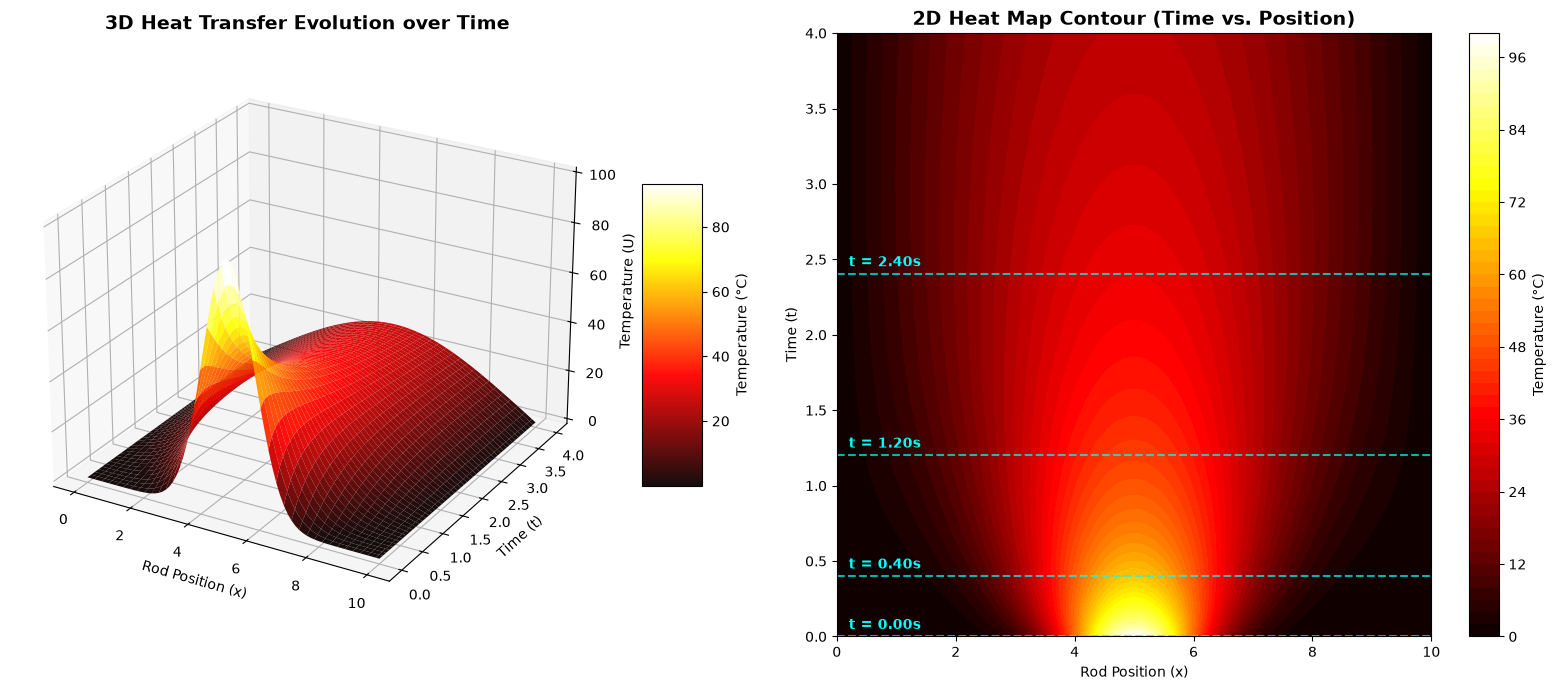

In [3]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Create Spatiotemporal Grids for plotting
X_mesh, T_mesh = np.meshgrid(x_grid, t_grid)
U_plot = U.T  # Transpose to match dimensions (time steps x spatial steps)

fig = plt.figure(figsize=(16, 7))

# --- Left Panel: 3D Heat Diffusion Surface Map ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf = ax1.plot_surface(X_mesh, T_mesh, U_plot, cmap='hot', edgecolor='none', alpha=0.95)
fig.colorbar(surf, ax=ax1, shrink=0.5, aspect=5, label='Temperature (°C)')
ax1.set_title('3D Heat Transfer Evolution over Time', fontsize=14, fontweight='bold')
ax1.set_xlabel('Rod Position (x)')
ax1.set_ylabel('Time (t)')
ax1.set_zlabel('Temperature (U)')
ax1.view_init(elev=25, azim=-60)

# --- Right Panel: 2D Spatial-Temporal Temperature Contour Plot ---
ax2 = fig.add_subplot(1, 2, 2)
contour = ax2.contourf(X_mesh, T_mesh, U_plot, levels=50, cmap='hot')
fig.colorbar(contour, ax=ax2, label='Temperature (°C)')

# Highlight some specific time slices as lines
time_snapshots = [0, int(Nt*0.1), int(Nt*0.3), int(Nt*0.6)]
for step in time_snapshots:
    ax2.axhline(y=t_grid[step], color='cyan', linestyle='--', alpha=0.7)
    ax2.text(0.2, t_grid[step] + 0.05, f't = {t_grid[step]:.2f}s', color='cyan', fontsize=10, weight='bold')

ax2.set_title('2D Heat Map Contour (Time vs. Position)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Rod Position (x)')
ax2.set_ylabel('Time (t)')

plt.tight_layout()
plt.show()

### 1c. Implicit finite differences

Evaluate the space derivative at the **new** time level instead:

$$-r\,u_{i-1}^{n+1} + (1 + 2r)\,u_i^{n+1} - r\,u_{i+1}^{n+1} = u_i^n$$

Each step solves a tridiagonal system (Thomas algorithm via `solve_banded`). It is stable for any $r$, so the time step can be larger than FTCS allows.

In [4]:
import time
import numpy as np
from scipy.linalg import solve_banded

# 1. Physical and Numerical Parameters
L = 10.0        # Length of the metal rod
T_max = 4.0     # Total simulation time
alpha = 1.2     # Thermal diffusivity coefficient

Nx = 80         # Number of spatial grid points
Nt = 500        # Number of time steps (can now be much smaller!)

x_grid = np.linspace(0, L, Nx)
t_grid = np.linspace(0, T_max, Nt)

dx = x_grid[1] - x_grid[0]
dt = t_grid[1] - t_grid[0]
r = alpha * dt / (dx**2)

print(f"Implicit Solver -> dt: {dt:.6f}, Nt: {Nt}, Fourier number r: {r:.4f} (No stability limit!)")

# 2. Initialize temperature grid U(x, t)
U = np.zeros((Nx, Nt))
U[:, 0] = 100.0 * np.exp(-((x_grid - L/2)**2) / 1.5)
U[0, :] = 0.0
U[-1, :] = 0.0

# 3. Assemble Tridiagonal Matrix in Banded Format (3 diagonals x M interior nodes)
M = Nx - 2  # Number of interior unknowns
ab = np.zeros((3, M))
ab[0, 1:] = -r          # Upper diagonal
ab[1, :]  = 1.0 + 2*r   # Main diagonal
ab[2, :-1] = -r         # Lower diagonal

# 4. Implicit Time-Stepping Loop (Thomas Algorithm via LAPACK)
start = time.perf_counter()
for t in range(Nt - 1):
    # Right-hand side is simply the interior temperature at step t
    rhs = U[1:-1, t]
    U[1:-1, t+1] = solve_banded((1, 1), ab, rhs)

elapsed = (time.perf_counter() - start) * 1000
print(f"Solved in {elapsed:.2f} ms | Max final temp: {U[:, -1].max():.4f} °C")

explU = U.copy()


Implicit Solver -> dt: 0.008016, Nt: 500, Fourier number r: 0.6003 (No stability limit!)
Solved in 14.56 ms | Max final temp: 26.5013 °C


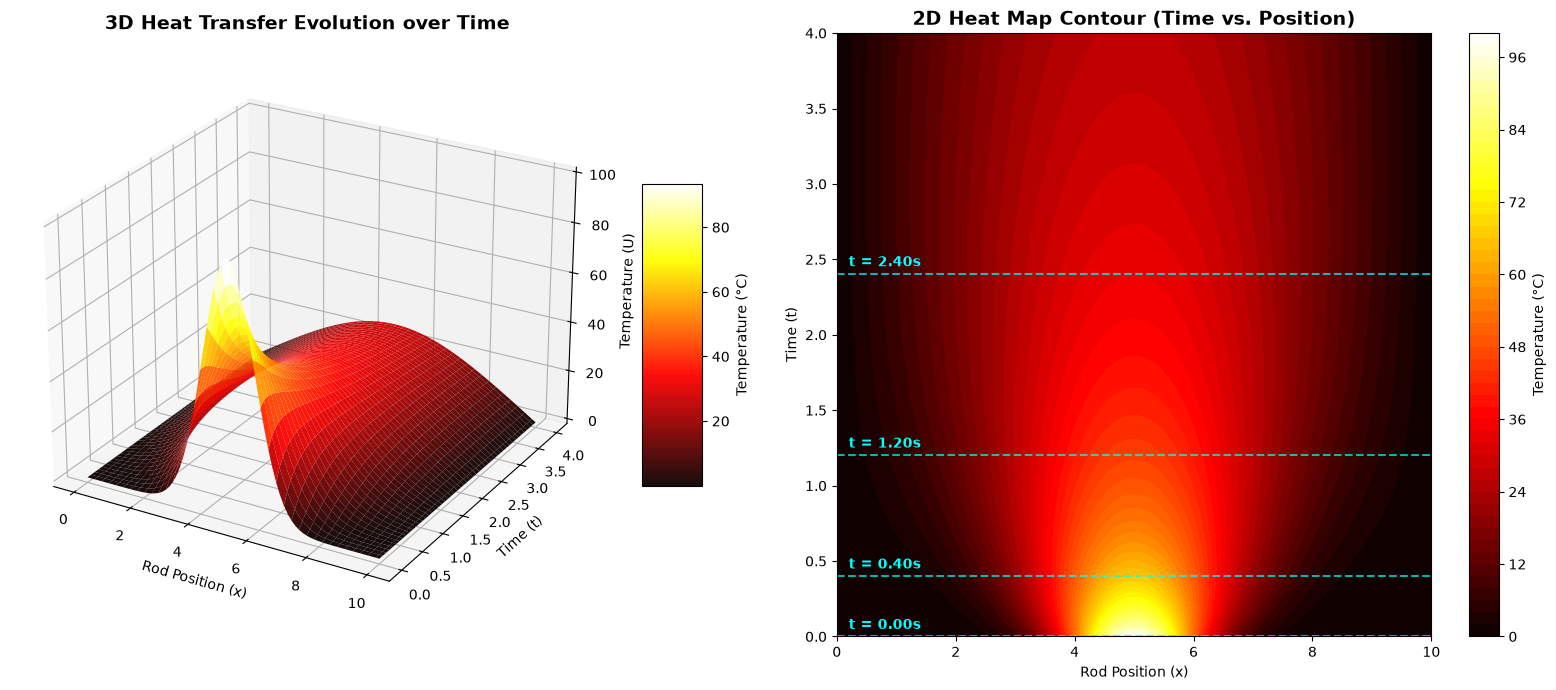

In [5]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Create Spatiotemporal Grids for plotting
X_mesh, T_mesh = np.meshgrid(x_grid, t_grid)
U_plot = U.T  # Transpose to match dimensions (time steps x spatial steps)

fig = plt.figure(figsize=(16, 7))

# --- Left Panel: 3D Heat Diffusion Surface Map ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf = ax1.plot_surface(X_mesh, T_mesh, U_plot, cmap='hot', edgecolor='none', alpha=0.95)
fig.colorbar(surf, ax=ax1, shrink=0.5, aspect=5, label='Temperature (°C)')
ax1.set_title('3D Heat Transfer Evolution over Time', fontsize=14, fontweight='bold')
ax1.set_xlabel('Rod Position (x)')
ax1.set_ylabel('Time (t)')
ax1.set_zlabel('Temperature (U)')
ax1.view_init(elev=25, azim=-60)

# --- Right Panel: 2D Spatial-Temporal Temperature Contour Plot ---
ax2 = fig.add_subplot(1, 2, 2)
contour = ax2.contourf(X_mesh, T_mesh, U_plot, levels=50, cmap='hot')
fig.colorbar(contour, ax=ax2, label='Temperature (°C)')

# Highlight some specific time slices as lines
time_snapshots = [0, int(Nt*0.1), int(Nt*0.3), int(Nt*0.6)]
for step in time_snapshots:
    ax2.axhline(y=t_grid[step], color='cyan', linestyle='--', alpha=0.7)
    ax2.text(0.2, t_grid[step] + 0.05, f't = {t_grid[step]:.2f}s', color='cyan', fontsize=10, weight='bold')

ax2.set_title('2D Heat Map Contour (Time vs. Position)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Rod Position (x)')
ax2.set_ylabel('Time (t)')

plt.tight_layout()
plt.show()

### 1d. Comparison

Note: the explicit solver (1a) stores its result in `implU` and the implicit solver (1c) in `explU`, so the names are swapped. The comparison below is unaffected.

In [6]:
# Fix the swapped labels first:
# explU = explicit result (80, 600), implU = implicit result (80, 500)

diff_final = explU[:, -1] - implU[:, -1]
print("Max difference at t = 4.0s:", np.max(np.abs(diff_final)))


Max difference at t = 4.0s: 0.022182616933172028


## Part 2: Heat in a plate (2D)

$$\frac{\partial u}{\partial t} = \alpha\left(\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2}\right)$$

A square plate of side $L = 10$ with two hot spots, all four edges held at $0^\circ$C, $\alpha = 1.2$.

**Explicit scheme (5-point stencil):**

$$u_{i,j}^{n+1} = u_{i,j}^n + r\left(u_{i+1,j}^n + u_{i-1,j}^n + u_{i,j+1}^n + u_{i,j-1}^n - 4u_{i,j}^n\right)$$

The bracket is $4\times$(average of the 4 neighbours $-$ the point itself): the discrete Laplacian. Stability now needs $r \le 0.25$, half of the 1D limit, because each point has twice as many neighbours.

**Analytical reference (double Fourier series):**

$$u(x, y, t) = \sum_{m, n} B_{mn}\, \sin\frac{m\pi x}{L}\, \sin\frac{n\pi y}{L}\, e^{-\alpha\pi^2 (m^2 + n^2)\, t / L^2}$$

**Heat balance (divergence theorem):** the total heat $H = \iint u\, dA$ can only change by heat crossing the edges:

$$\frac{dH}{dt} = \iint \alpha\,\nabla^2 u\, dA = \oint \alpha\,\nabla u\cdot\hat{\mathbf n}\, ds$$

In [7]:
# 2D HEAT EQUATION: explicit FTCS solver, analytical double Fourier series, heat balance
import time
import numpy as np
from scipy.fft import dstn

# 1. Physical and numerical parameters
L2 = 10.0          # plate side length
alpha2 = 1.2       # thermal diffusivity
T2_max = 4.0       # total simulation time
N2 = 81            # grid points per side (including the edges)

x2 = np.linspace(0, L2, N2)
y2 = np.linspace(0, L2, N2)
X2, Y2 = np.meshgrid(x2, y2)
h2 = x2[1] - x2[0]
r2 = 0.2                                   # must be <= 0.25 for stability in 2D
dt2 = r2 * h2**2 / alpha2
n_steps = int(np.ceil(T2_max / dt2))
dt2 = T2_max / n_steps
r2 = alpha2 * dt2 / h2**2
print(f"2D explicit solver -> h = {h2:.4f}, dt = {dt2:.6f}, steps = {n_steps}, r = {r2:.4f} (limit 0.25)")

# 2. Initial condition: two hot spots; Dirichlet edges u = 0
u0_2d = 100 * np.exp(-((X2 - 3.5)**2 + (Y2 - 6.0)**2) / 1.0) + 70 * np.exp(-((X2 - 6.5)**2 + (Y2 - 3.5)**2) / 0.6)
u0_2d[0, :] = u0_2d[-1, :] = u0_2d[:, 0] = u0_2d[:, -1] = 0.0

# 3. Time stepping with the 5-point stencil (vectorised)
snap_times = [0.0, 0.1, 0.5, 1.5, 4.0]
snap_steps = {int(round(t / dt2)): t for t in snap_times}
snapshots = {}
heat = np.zeros(n_steps + 1)               # total heat H = sum u dA
loss = np.zeros(n_steps + 1)               # cumulative heat lost through the edges
u2 = u0_2d.copy()
start = time.perf_counter()
for n in range(n_steps + 1):
    heat[n] = u2[1:-1, 1:-1].sum() * h2**2
    if n in snap_steps:
        snapshots[snap_steps[n]] = u2.copy()
    if n == n_steps:
        break
    # Edge flux: alpha * grad u . n ds  with one-sided differences, (0 - u_adjacent) / h * h
    edge_flux = -alpha2 * (u2[1, 1:-1].sum() + u2[-2, 1:-1].sum() + u2[1:-1, 1].sum() + u2[1:-1, -2].sum())
    loss[n + 1] = loss[n] + edge_flux * dt2
    lap = (u2[2:, 1:-1] + u2[:-2, 1:-1] + u2[1:-1, 2:] + u2[1:-1, :-2] - 4 * u2[1:-1, 1:-1])
    u2[1:-1, 1:-1] += r2 * lap
elapsed = (time.perf_counter() - start) * 1000
t2_grid = np.linspace(0, T2_max, n_steps + 1)

# 4. Analytical reference: double sine series with continuous decay rates
B = dstn(u0_2d[1:-1, 1:-1], type=1) / (2 * (N2 - 1))**2 * 4     # sine coefficients B_mn
modes = np.arange(1, N2 - 1)
Mg, Ng = np.meshgrid(modes, modes)                                # rows: y-mode n, cols: x-mode m
decay = np.exp(-alpha2 * np.pi**2 * (Mg**2 + Ng**2) * T2_max / L2**2)
u_exact_T = np.zeros_like(u0_2d)
u_exact_T[1:-1, 1:-1] = dstn(B * decay, type=1) / 4               # back to the grid at t = T2_max

print(f"Solved in {elapsed:.0f} ms | peak: {u0_2d.max():.2f} -> {u2.max():.2f} °C")
print(f"max |explicit - analytical| at t = {T2_max}: {np.abs(u2 - u_exact_T).max():.4f} °C "
      f"(peak {u_exact_T.max():.2f} °C)")
print(f"heat balance: H(T) - H(0) = {heat[-1] - heat[0]:.6f},  edge flux integrated = {loss[-1]:.6f},  "
      f"mismatch {abs(heat[-1] - heat[0] - loss[-1]):.1e}")

2D explicit solver -> h = 0.1250, dt = 0.002604, steps = 1536, r = 0.2000 (limit 0.25)
Solved in 49 ms | peak: 100.00 -> 5.68 °C
max |explicit - analytical| at t = 4.0: 0.0015 °C (peak 5.68 °C)
heat balance: H(T) - H(0) = -223.937411,  edge flux integrated = -223.937411,  mismatch 5.7e-14


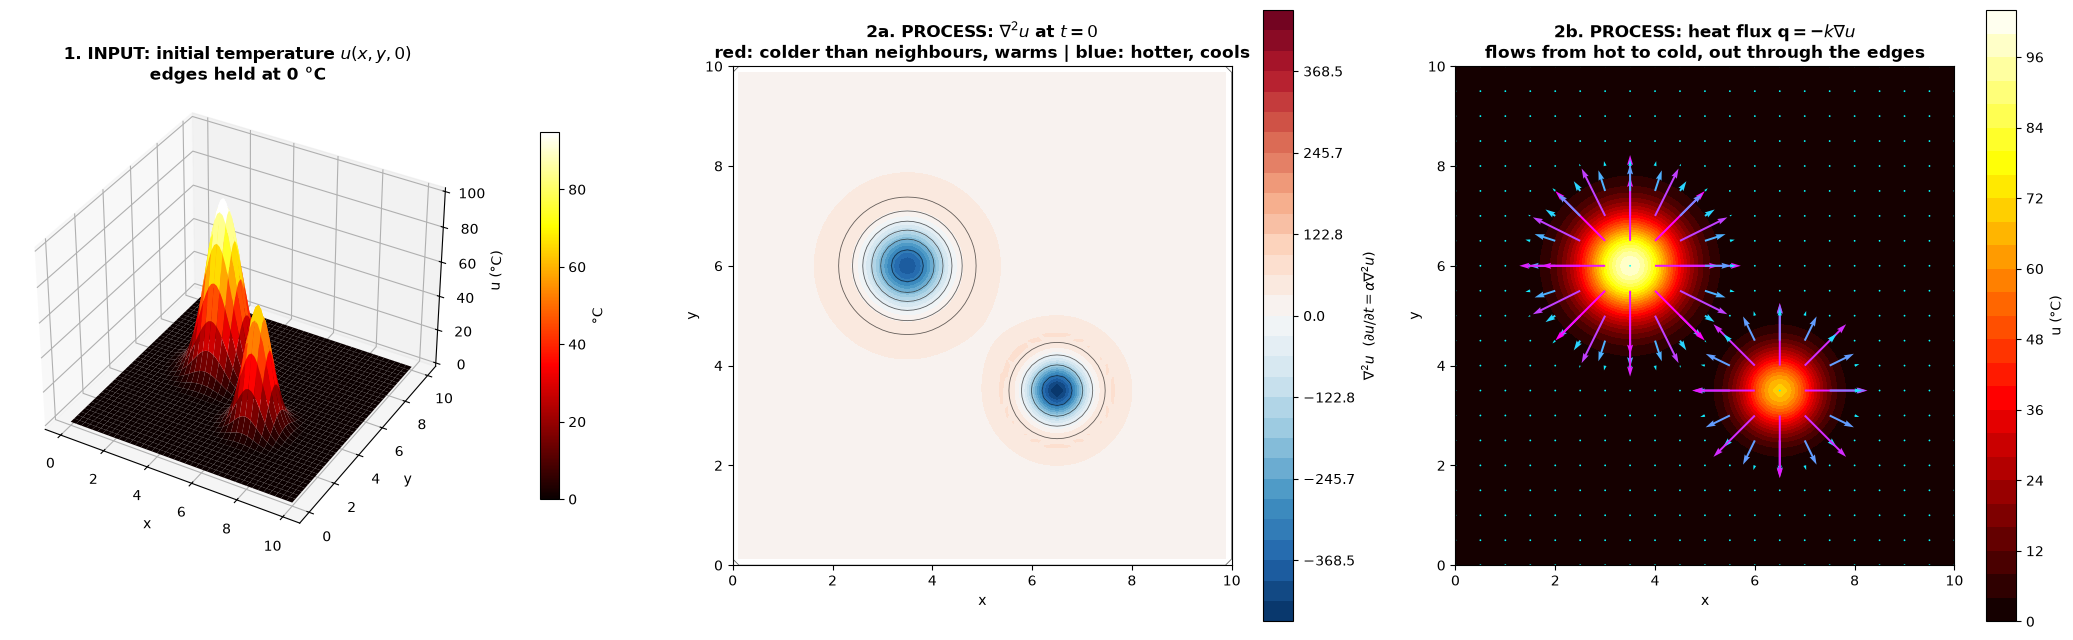

In [8]:
# 2D HEAT EQUATION, INPUT and PROCESS: initial plate, Laplacian (heating / cooling), heat flux q = -k grad u
import numpy as np
import matplotlib.pyplot as plt

u = u0_2d
lap0 = np.full_like(u, np.nan)
lap0[1:-1, 1:-1] = (u[2:, 1:-1] + u[:-2, 1:-1] + u[1:-1, 2:] + u[1:-1, :-2] - 4 * u[1:-1, 1:-1]) / h2**2
du_dy, du_dx = np.gradient(u, y2, x2)
qx, qy = -du_dx, -du_dy                     # heat flux direction (k = 1)

fig = plt.figure(figsize=(21, 6.5))

# Panel 1: INPUT
ax1 = fig.add_subplot(1, 3, 1, projection='3d')
surf = ax1.plot_surface(X2, Y2, u, cmap='hot', edgecolor='none')
ax1.set_title('1. INPUT: initial temperature $u(x, y, 0)$\nedges held at 0 °C', fontsize=12, fontweight='bold')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('u (°C)')
ax1.view_init(elev=35, azim=-60)
fig.colorbar(surf, ax=ax1, shrink=0.6, pad=0.12, label='°C')

# Panel 2a: PROCESS (Laplacian = local heating rate / alpha)
ax2 = fig.add_subplot(1, 3, 2)
vmax = np.nanmax(np.abs(lap0))
cf = ax2.contourf(X2, Y2, lap0, levels=np.linspace(-vmax, vmax, 31), cmap='RdBu_r')
ax2.contour(X2, Y2, u, levels=8, colors='k', linewidths=0.6, alpha=0.6)
ax2.set_title(r'2a. PROCESS: $\nabla^2 u$ at $t = 0$' + '\nred: colder than neighbours, warms | blue: hotter, cools',
              fontsize=12, fontweight='bold')
fig.colorbar(cf, ax=ax2, label=r'$\nabla^2 u$  ($\partial u/\partial t = \alpha\nabla^2 u$)')

# Panel 2b: PROCESS (heat flux flows down the gradient)
ax3 = fig.add_subplot(1, 3, 3)
cf3 = ax3.contourf(X2, Y2, u, levels=30, cmap='hot')
s = 4
mag = np.hypot(qx, qy)
ax3.quiver(X2[::s, ::s], Y2[::s, ::s], qx[::s, ::s], qy[::s, ::s], mag[::s, ::s], cmap='cool',
           scale_units='xy', scale=60, width=0.004)
ax3.set_title(r'2b. PROCESS: heat flux $\mathbf{q} = -k\nabla u$' + '\nflows from hot to cold, out through the edges',
              fontsize=12, fontweight='bold')
fig.colorbar(cf3, ax=ax3, label='u (°C)')

for ax in (ax2, ax3):
    ax.set_aspect('equal')
    ax.set_xlabel('x')
    ax.set_ylabel('y')

plt.tight_layout()
plt.show()

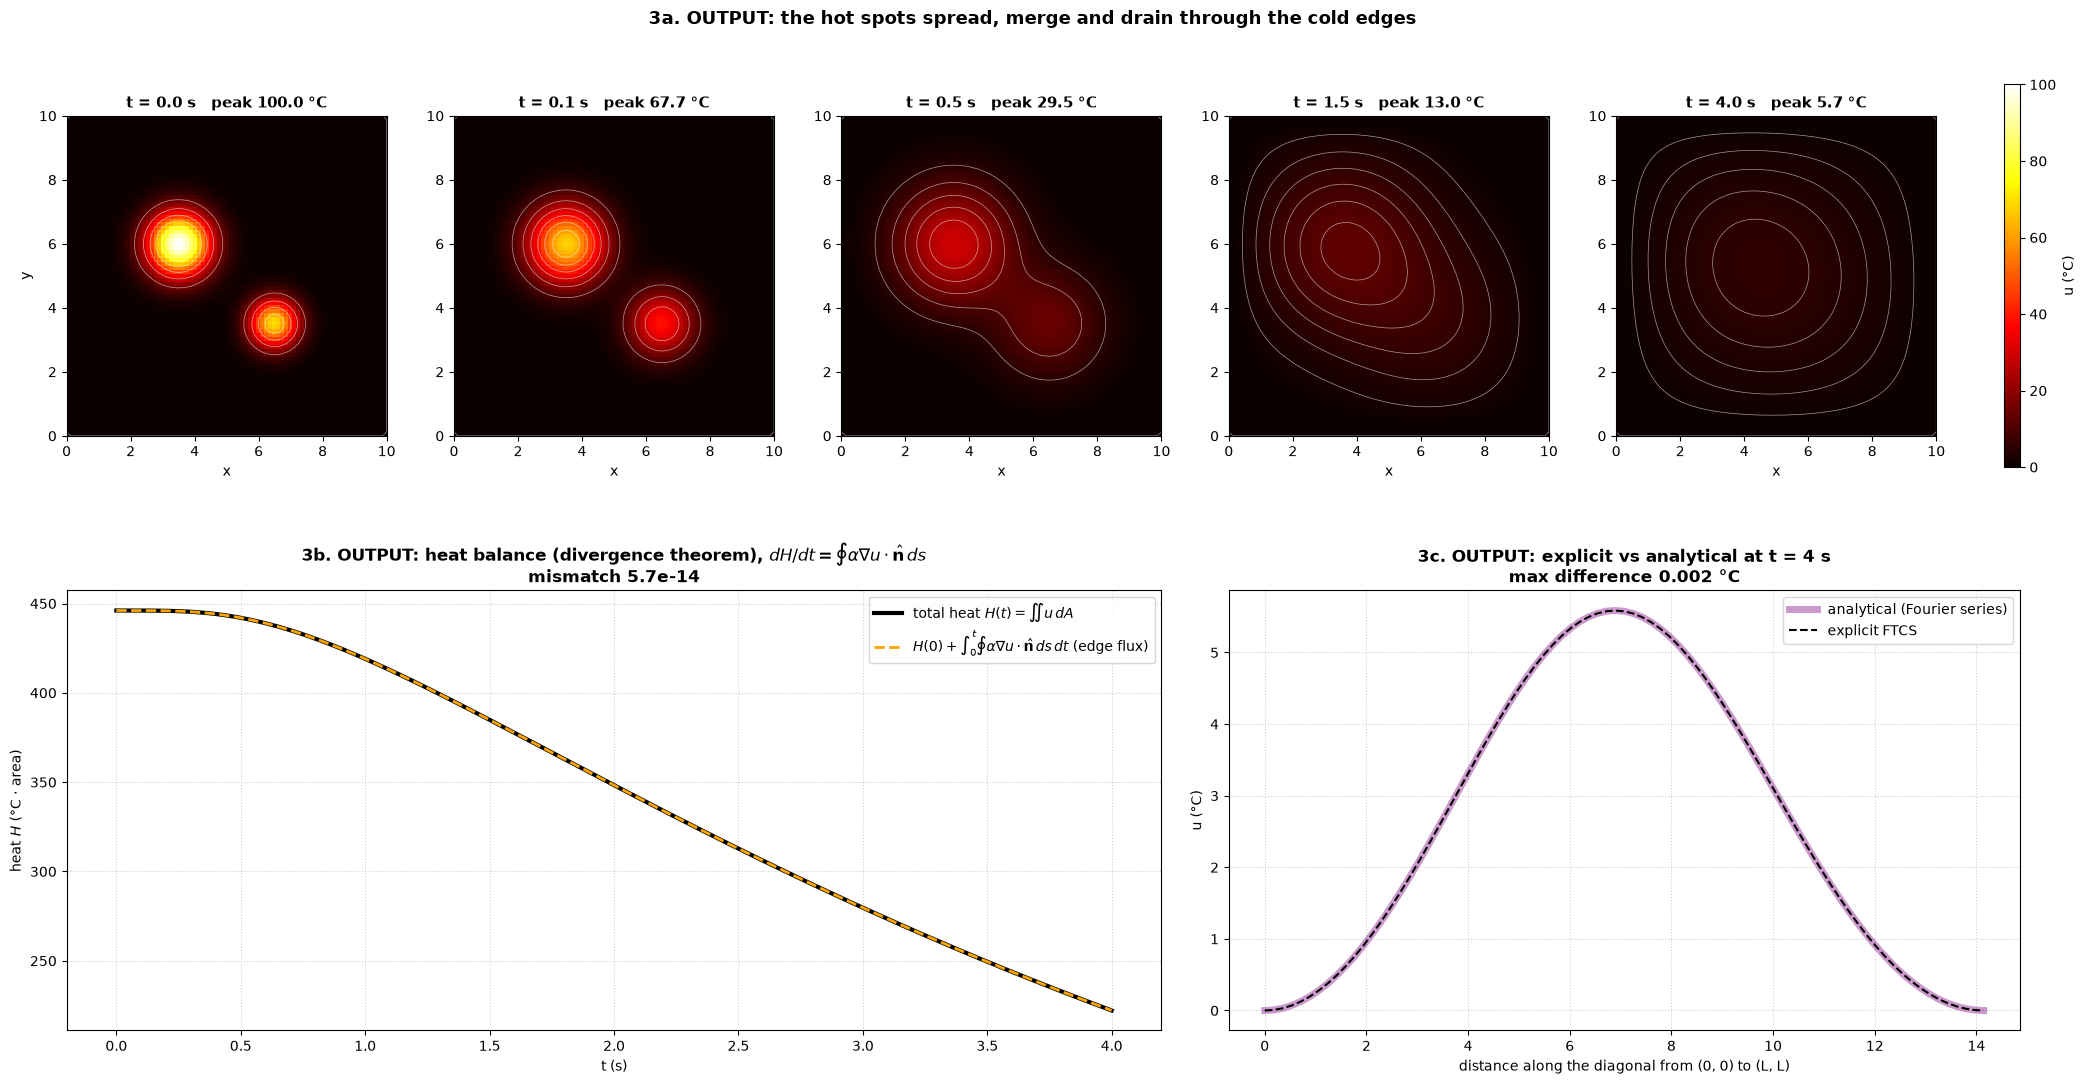

In [9]:
# 2D HEAT EQUATION, OUTPUT: evolution, heat balance, comparison with the analytical solution
import numpy as np
import matplotlib.pyplot as plt

n_snap = len(snap_times)
fig = plt.figure(figsize=(21, 11))
gs = fig.add_gridspec(2, n_snap + 1, width_ratios=[1] * n_snap + [0.05], height_ratios=[1, 1.15])

# Row 1: snapshots on a shared colour scale
vmax = u0_2d.max()
for k, t in enumerate(snap_times):
    ax = fig.add_subplot(gs[0, k])
    im = ax.imshow(snapshots[t], origin='lower', extent=[0, L2, 0, L2], cmap='hot', vmin=0, vmax=vmax)
    ax.contour(X2, Y2, snapshots[t], levels=6, colors='w', linewidths=0.5, alpha=0.6)
    ax.set_title(f't = {t:.1f} s   peak {snapshots[t].max():.1f} °C', fontsize=11, fontweight='bold')
    ax.set_xlabel('x')
    if k == 0:
        ax.set_ylabel('y')
fig.colorbar(im, cax=fig.add_subplot(gs[0, n_snap]), label='u (°C)')
fig.text(0.5, 0.975, '3a. OUTPUT: the hot spots spread, merge and drain through the cold edges',
         ha='center', fontsize=13, fontweight='bold')

# Row 2 left: heat balance
ax_h = fig.add_subplot(gs[1, :3])
ax_h.plot(t2_grid, heat, 'k-', lw=3, label=r'total heat $H(t) = \iint u\, dA$')
ax_h.plot(t2_grid, heat[0] + loss, '--', color='orange', lw=2,
          label=r'$H(0) + \int_0^t \oint \alpha\nabla u\cdot\hat{\mathbf{n}}\, ds\, dt$ (edge flux)')
ax_h.set_xlabel('t (s)')
ax_h.set_ylabel(r'heat $H$ (°C $\cdot$ area)')
ax_h.grid(True, linestyle=':', alpha=0.6)
ax_h.legend(loc='upper right')
ax_h.set_title(r'3b. OUTPUT: heat balance (divergence theorem), $dH/dt = \oint \alpha\nabla u\cdot\hat{\mathbf{n}}\, ds$'
               + f'\nmismatch {abs(heat[-1] - heat[0] - loss[-1]):.1e}', fontsize=12, fontweight='bold')

# Row 2 right: explicit vs analytical along the diagonal at the final time
ax_c = fig.add_subplot(gs[1, 3:n_snap + 1])
diag = np.arange(N2)
s_diag = np.hypot(x2, y2)
ax_c.plot(s_diag, u_exact_T[diag, diag], color='purple', lw=5, alpha=0.4, label='analytical (Fourier series)')
ax_c.plot(s_diag, u2[diag, diag], 'k--', lw=1.5, label='explicit FTCS')
ax_c.set_xlabel('distance along the diagonal from (0, 0) to (L, L)')
ax_c.set_ylabel('u (°C)')
ax_c.grid(True, linestyle=':', alpha=0.6)
ax_c.legend(loc='upper right')
ax_c.set_title(f'3c. OUTPUT: explicit vs analytical at t = {T2_max:.0f} s\n'
               f'max difference {np.abs(u2 - u_exact_T).max():.3f} °C', fontsize=12, fontweight='bold')

plt.subplots_adjust(top=0.92, bottom=0.06, left=0.04, right=0.97, hspace=0.3, wspace=0.25)
plt.show()

## Part 3: Pressure diffusion around a well

A well produces oil or water at a constant rate $q$ from a large, uniform reservoir layer of thickness $h$. As fluid leaves, the pressure near the well drops, and this drop spreads outward by diffusion.

**Derivation, step by step:**
1. **Darcy's law (gradient):** fluid flows from high to low pressure, $\mathbf v = -\dfrac{k}{\mu}\nabla p$, where $k$ is the rock permeability and $\mu$ the fluid viscosity.
2. **Mass conservation (divergence theorem):** the rock and fluid are slightly compressible, so a region stores fluid when its pressure rises: $\phi\, c_t\, \partial_t p = -\nabla\cdot\mathbf v$.
3. **Combine:** $\partial_t p = \eta\,\nabla^2 p$ with hydraulic diffusivity $\eta = \dfrac{k}{\phi\,\mu\,c_t}$.

The flow is radial, so the Laplacian takes its cylindrical form:

$$\frac{\partial p}{\partial t} = \eta\,\frac{1}{r}\frac{\partial}{\partial r}\left(r\,\frac{\partial p}{\partial r}\right), \qquad \text{at the well: } 2\pi r h\,\frac{k}{\mu}\frac{\partial p}{\partial r} = q$$

**Exact solution (Theis, line source in an infinite reservoir):**

$$\Delta p(r, t) = p_i - p(r, t) = \frac{q\mu}{4\pi k h}\, E_1\!\left(\frac{r^2}{4\eta t}\right), \qquad E_1(x) = \int_x^\infty \frac{e^{-s}}{s}\, ds$$

Two consequences used in well testing:
- **Semilog straight line:** for $r^2 / (4\eta t) < 0.01$, $E_1(x) \approx -\ln x - 0.5772$. The pressure drop at the well then grows linearly with $\log_{10} t$, with slope $m = 2.303\,\dfrac{q\mu}{4\pi k h}$ per decade, so the **permeability can be read from the slope**: $k = 2.303\,\dfrac{q\mu}{4\pi h\, m}$.
- **Radius of investigation:** the flow rate through a circle of radius $r$ is $q\,e^{-r^2/(4\eta t)}$. It falls to $q/e$ at $r_{inv} = \sqrt{4\eta t}$. That is how far the test has "seen" into the reservoir after time $t$.

**Numerical method:** implicit finite volumes on rings whose width grows geometrically away from the well (fine near the well, where pressure changes fast), with time steps that also grow geometrically.

In [10]:
# PRESSURE DIFFUSION: radial implicit finite-volume solver vs Theis line-source solution
import numpy as np
from scipy.linalg import solve_banded
from scipy.special import exp1

# 1. Reservoir, fluid and well properties (SI units)
mD = 9.869233e-16                  # 1 millidarcy in m^2
k = 100 * mD                       # permeability
mu = 1.0e-3                        # viscosity (Pa s), water-like
phi = 0.20                         # porosity
ct = 1.0e-9                        # total compressibility (1/Pa)
h = 10.0                           # layer thickness (m)
q = 0.005                          # production rate (m^3/s), about 430 m^3/day
p_i = 30.0e6                       # initial reservoir pressure (Pa)
rw, re = 0.1, 20000.0              # well radius, outer radius (m); re far enough to act as infinite
eta = k / (phi * mu * ct)          # hydraulic diffusivity (m^2/s)
coef = q * mu / (4 * np.pi * k * h)
print(f"hydraulic diffusivity eta = {eta:.3f} m^2/s,  q mu / (4 pi k h) = {coef / 1e6:.3f} MPa")

# 2. Radial grid: N rings with geometrically growing width
N = 250
rf = np.geomspace(rw, re, N + 1)                 # ring faces
rc = np.sqrt(rf[:-1] * rf[1:])                   # ring centres
S = phi * ct * np.pi * h * (rf[1:]**2 - rf[:-1]**2)          # storage of each ring (m^3/Pa)
T = 2 * np.pi * h * k / mu * rf[1:-1] / np.diff(rc)          # flow conductance between rings

# 3. Implicit time stepping:  S dp/dt = T_right (p_right - p) - T_left (p - p_left) - q (first ring)
t_end = 10 * 86400.0
t = np.concatenate([[0.0], np.geomspace(1.0, t_end, 400)])
p = np.full(N, p_i)
P = np.empty((len(t), N))
P[0] = p
T_left = np.concatenate([[0.0], T])
T_right = np.concatenate([T, [0.0]])             # no flow through the outer boundary
src = np.zeros(N)
src[0] = -q                                      # the well withdraws q from the first ring
for n in range(1, len(t)):
    dt = t[n] - t[n - 1]
    ab = np.zeros((3, N))
    ab[0, 1:] = -T
    ab[1] = S / dt + T_left + T_right
    ab[2, :-1] = -T
    p = solve_banded((1, 1), ab, S / dt * p + src)
    P[n] = p
dP = p_i - P                                     # pressure drop (Pa)


# 4. Theis line-source solution
def theis(r, tt):
    return coef * exp1(r**2 / (4 * eta * tt))


# 5. Checks
check_times = np.array([0.1, 1.0, 10.0]) * 86400
print("\nnumerical vs Theis (pressure drop in MPa):")
for tt in check_times:
    n = np.argmin(np.abs(t - tt))
    for r in (1.0, 10.0, 100.0):
        num = np.interp(np.log(r), np.log(rc), dP[n])
        print(f"  t = {t[n] / 86400:5.1f} d, r = {r:5.0f} m: numerical {num / 1e6:.4f}, Theis {theis(r, t[n]) / 1e6:.4f}")

# Semilog analysis at the well: fit dp = m log10(t) + b over 1 h .. 10 days
dPw = dP[:, 0]
late = t >= 3600
m, b = np.polyfit(np.log10(t[late]), dPw[late], 1)
k_est = 2.303 * q * mu / (4 * np.pi * h * m)
print(f"\nwell pressure drop after 10 days: {dPw[-1] / 1e6:.3f} MPa (Theis at r = {rc[0]:.3f} m: {theis(rc[0], t[-1]) / 1e6:.3f})")
print(f"semilog slope m = {m / 1e6:.4f} MPa per decade  ->  permeability from slope = {k_est / mD:.2f} mD (true {k / mD:.0f} mD)")

hydraulic diffusivity eta = 0.493 m^2/s,  q mu / (4 pi k h) = 0.403 MPa

numerical vs Theis (pressure drop in MPa):
  t =   0.1 d, r =     1 m: numerical 3.6984, Theis 3.7016
  t =   0.1 d, r =    10 m: numerical 1.8439, Theis 1.8473
  t =   0.1 d, r =   100 m: numerical 0.1906, Theis 0.1916
  t =   1.0 d, r =     1 m: numerical 4.6238, Theis 4.6270
  t =   1.0 d, r =    10 m: numerical 2.7673, Theis 2.7706
  t =   1.0 d, r =   100 m: numerical 0.9337, Theis 0.9369
  t =  10.0 d, r =     1 m: numerical 5.5493, Theis 5.5523
  t =  10.0 d, r =    10 m: numerical 3.6925, Theis 3.6958
  t =  10.0 d, r =   100 m: numerical 1.8381, Theis 1.8415

well pressure drop after 10 days: 7.386 MPa (Theis at r = 0.102 m: 7.389)
semilog slope m = 0.9284 MPa per decade  ->  permeability from slope = 100.01 mD (true 100 mD)


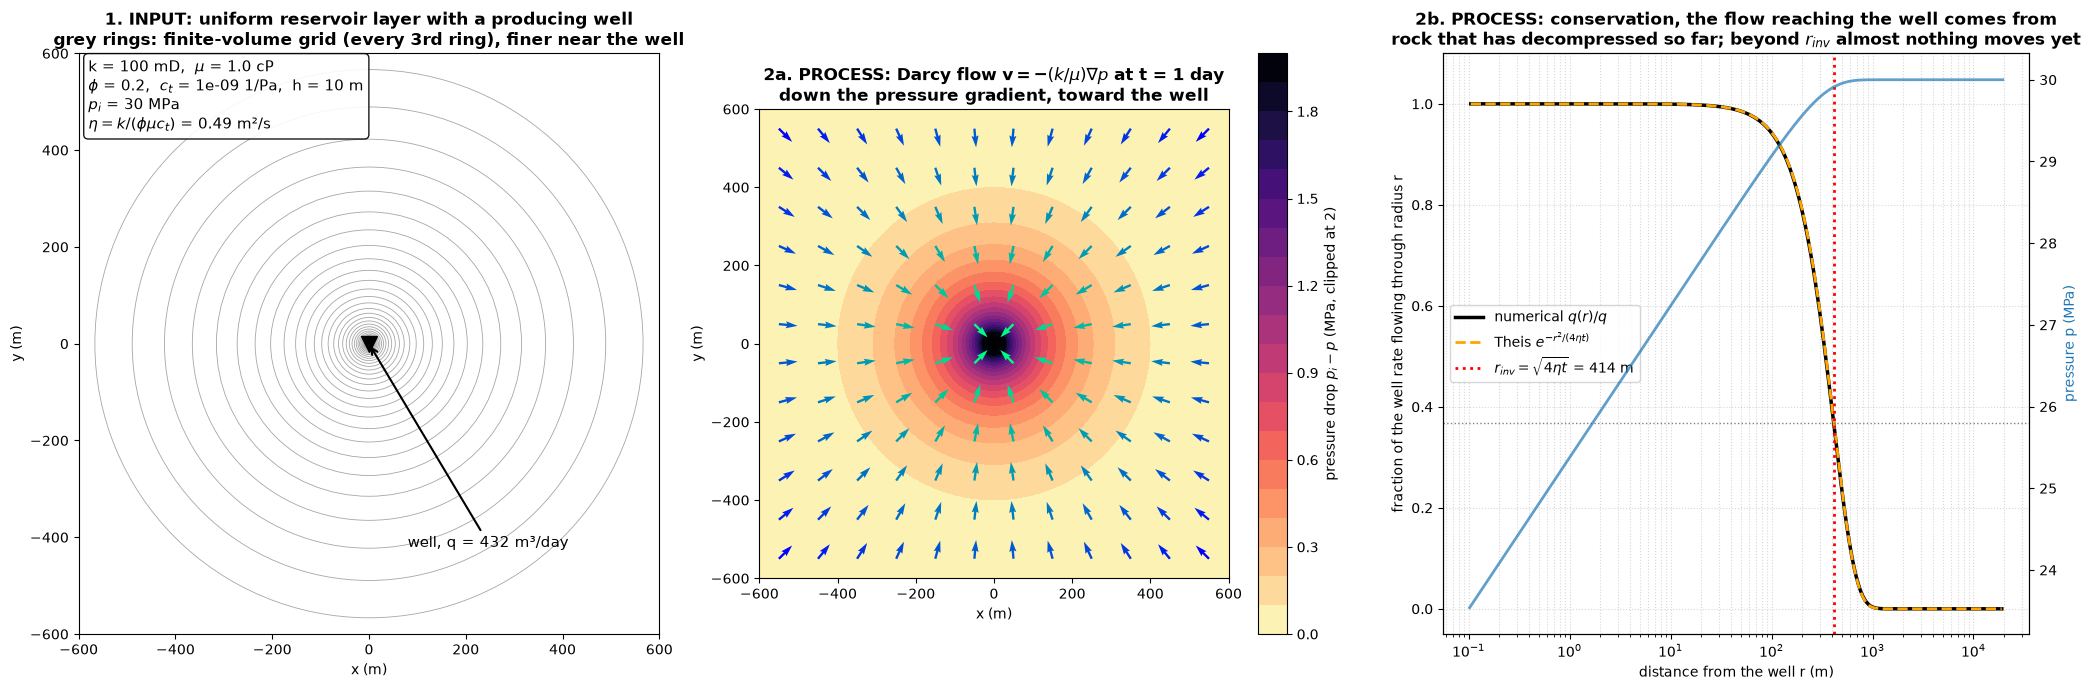

In [11]:
# PRESSURE DIFFUSION, INPUT and PROCESS: reservoir + grid, Darcy flux toward the well, flow carried through each radius
import numpy as np
import matplotlib.pyplot as plt

day = 86400.0
n1 = np.argmin(np.abs(t - 1 * day))              # snapshot at 1 day
fig = plt.figure(figsize=(21, 7))

# Panel 1: INPUT (reservoir, well, radial grid)
ax1 = fig.add_subplot(1, 3, 1)
for rr in rf[(rf > 5) & (rf < 600)][::3]:
    ax1.add_patch(plt.Circle((0, 0), rr, fill=False, color='gray', lw=0.6, alpha=0.7))
ax1.plot(0, 0, 'kv', ms=12)
ax1.annotate(f'well, q = {q * 86400:.0f} m³/day', xy=(0, 0), xytext=(80, -420), fontsize=11,
             arrowprops=dict(arrowstyle='->', lw=1.5))
props = (f'k = {k / mD:.0f} mD,  $\\mu$ = {mu * 1e3:.1f} cP\n'
         f'$\\phi$ = {phi},  $c_t$ = {ct:.0e} 1/Pa,  h = {h:.0f} m\n'
         f'$p_i$ = {p_i / 1e6:.0f} MPa\n'
         f'$\\eta = k/(\\phi\\mu c_t)$ = {eta:.2f} m²/s')
ax1.text(-580, 590, props, va='top', fontsize=11, bbox=dict(boxstyle='round', fc='w', alpha=0.9))
ax1.set_xlim(-600, 600)
ax1.set_ylim(-600, 600)
ax1.set_title('1. INPUT: uniform reservoir layer with a producing well\n'
              'grey rings: finite-volume grid (every 3rd ring), finer near the well',
              fontsize=12, fontweight='bold')

# Panel 2a: PROCESS (Darcy velocity field at 1 day)
ax2 = fig.add_subplot(1, 3, 2)
g = np.linspace(-600, 600, 241)
GX, GY = np.meshgrid(g, g)
GR = np.maximum(np.hypot(GX, GY), rw)
dmap = np.interp(np.log(GR), np.log(rc), dP[n1]) / 1e6
cf = ax2.contourf(GX, GY, np.minimum(dmap, 2.0), levels=np.linspace(0, 2, 21), cmap='magma_r')
fig.colorbar(cf, ax=ax2, label='pressure drop $p_i - p$ (MPa, clipped at 2)')
s = 20
dpdr = np.interp(np.log(GR), np.log(rc[:-1] * 1.0), np.diff(P[n1]) / np.diff(rc))   # dp/dr > 0 (pressure rises outward)
vr = -k / mu * dpdr                                               # Darcy velocity, negative = toward the well
ux, uy = vr * GX / GR, vr * GY / GR
mag = np.hypot(ux, uy)
ax2.quiver(GX[s // 2::s, s // 2::s], GY[s // 2::s, s // 2::s],
           (ux / np.where(mag > 0, mag, 1))[s // 2::s, s // 2::s], (uy / np.where(mag > 0, mag, 1))[s // 2::s, s // 2::s],
           np.log10(mag[s // 2::s, s // 2::s] + 1e-12), cmap='winter', scale=25, width=0.005)
ax2.plot(0, 0, 'kv', ms=10)
ax2.set_title(r'2a. PROCESS: Darcy flow $\mathbf{v} = -(k/\mu)\nabla p$ at t = 1 day' + '\n'
              'down the pressure gradient, toward the well',
              fontsize=12, fontweight='bold')

for ax in (ax1, ax2):
    ax.set_aspect('equal')
    ax.set_xlabel('x (m)')
    ax.set_ylabel('y (m)')

# Panel 2b: PROCESS (flow rate through each circle, and the pressure profile)
ax3 = fig.add_subplot(1, 3, 3)
q_r = 2 * np.pi * rf[1:-1] * h * k / mu * np.diff(P[n1]) / np.diff(rc)     # flow toward the well through radius r
r_inv = np.sqrt(4 * eta * t[n1])
ax3.semilogx(rf[1:-1], q_r / q, 'k-', lw=2.5, label=r'numerical $q(r) / q$')
ax3.semilogx(rf[1:-1], np.exp(-rf[1:-1]**2 / (4 * eta * t[n1])), '--', color='orange', lw=2,
             label=r'Theis $e^{-r^2/(4\eta t)}$')
ax3.axvline(r_inv, color='red', ls=':', lw=2, label=rf'$r_{{inv}} = \sqrt{{4\eta t}}$ = {r_inv:.0f} m')
ax3.axhline(np.exp(-1), color='gray', ls=':', lw=1)
ax3.set_xlabel('distance from the well r (m)')
ax3.set_ylabel('fraction of the well rate flowing through radius r')
ax3.set_ylim(-0.05, 1.1)
ax3b = ax3.twinx()
ax3b.semilogx(rc, P[n1] / 1e6, color='tab:blue', lw=2, alpha=0.7)
ax3b.set_ylabel('pressure p (MPa)', color='tab:blue')
ax3.legend(loc='center left')
ax3.grid(True, which='both', linestyle=':', alpha=0.5)
ax3.set_title('2b. PROCESS: conservation, the flow reaching the well comes from\n'
              'rock that has decompressed so far; beyond $r_{inv}$ almost nothing moves yet',
              fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

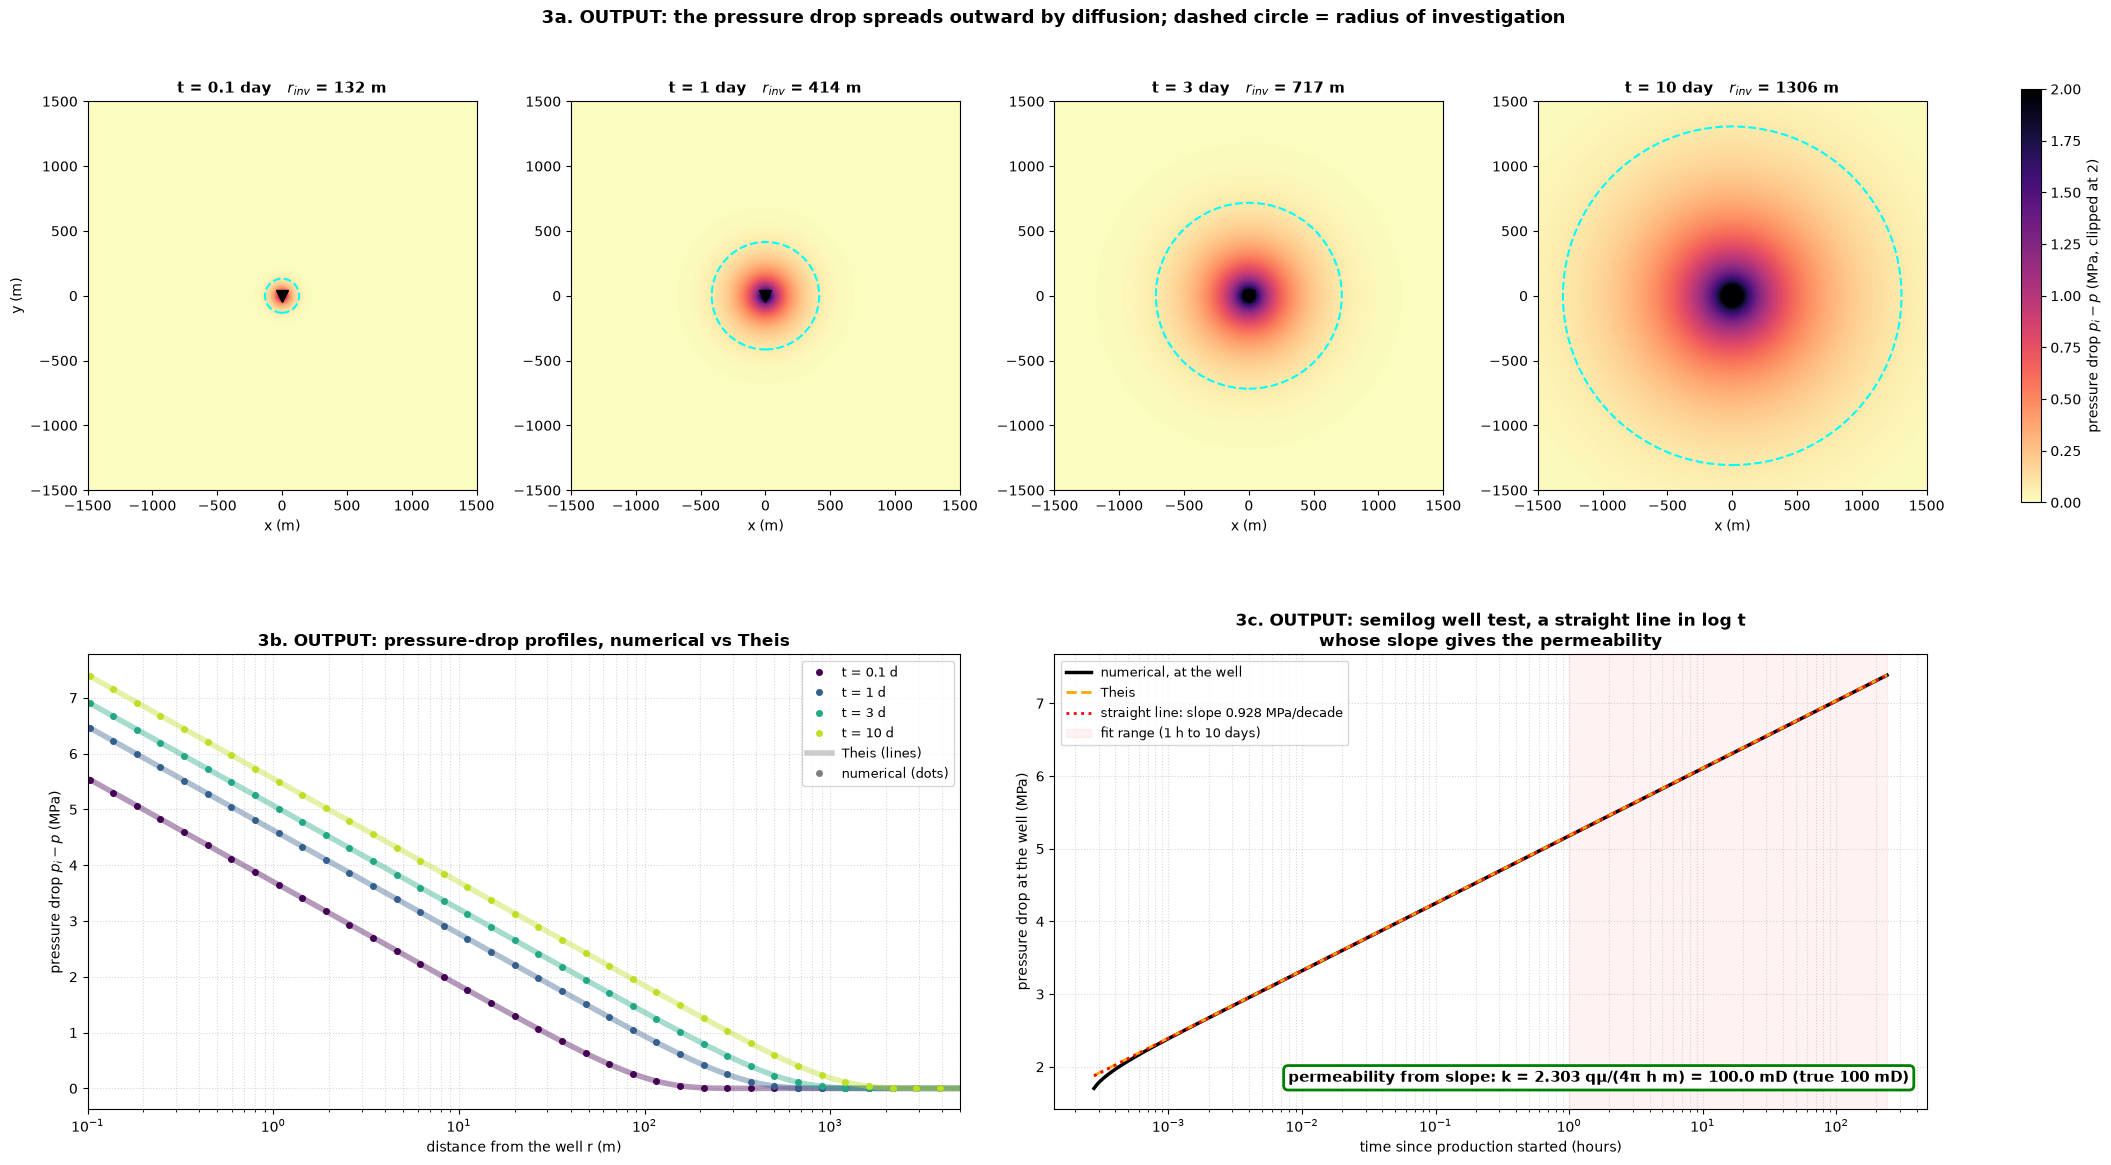

In [12]:
# PRESSURE DIFFUSION, OUTPUT: spreading drawdown, numerical vs Theis, semilog well test, radius of investigation
import numpy as np
import matplotlib.pyplot as plt

day = 86400.0
snap = [0.1, 1.0, 3.0, 10.0]
fig = plt.figure(figsize=(21, 12))
gs = fig.add_gridspec(2, len(snap) + 1, width_ratios=[1] * len(snap) + [0.05], height_ratios=[1, 1.1])

# Row 1: drawdown maps
g = np.linspace(-1500, 1500, 301)
GX, GY = np.meshgrid(g, g)
GR = np.maximum(np.hypot(GX, GY), rw)
vmax = 2.0
for j, td in enumerate(snap):
    n = np.argmin(np.abs(t - td * day))
    ax = fig.add_subplot(gs[0, j])
    dmap = np.interp(np.log(GR), np.log(rc), dP[n]) / 1e6
    im = ax.imshow(dmap, origin='lower', extent=[-1500, 1500, -1500, 1500], cmap='magma_r', vmin=0, vmax=vmax)
    ax.add_patch(plt.Circle((0, 0), np.sqrt(4 * eta * t[n]), fill=False, ls='--', color='cyan', lw=1.5))
    ax.plot(0, 0, 'kv', ms=8)
    ax.set_title(f't = {td:g} day   $r_{{inv}}$ = {np.sqrt(4 * eta * t[n]):.0f} m', fontsize=11, fontweight='bold')
    ax.set_xlabel('x (m)')
    if j == 0:
        ax.set_ylabel('y (m)')
fig.colorbar(im, cax=fig.add_subplot(gs[0, len(snap)]), label='pressure drop $p_i - p$ (MPa, clipped at 2)')
fig.text(0.5, 0.975, '3a. OUTPUT: the pressure drop spreads outward by diffusion; dashed circle = radius of investigation',
         ha='center', fontsize=13, fontweight='bold')

# Row 2 left: profiles, numerical vs Theis
ax = fig.add_subplot(gs[1, 0:2])
r_line = np.geomspace(rw, 5000, 300)
colors = plt.cm.viridis(np.linspace(0, 0.9, len(snap)))
for td, col in zip(snap, colors):
    n = np.argmin(np.abs(t - td * day))
    ax.semilogx(r_line, theis(r_line, t[n]) / 1e6, color=col, lw=4, alpha=0.4)
    ax.semilogx(rc[::6], dP[n, ::6] / 1e6, 'o', color=col, ms=4, label=f't = {td:g} d')
ax.plot([], [], color='gray', lw=4, alpha=0.4, label='Theis (lines)')
ax.plot([], [], 'o', color='gray', ms=4, label='numerical (dots)')
ax.set_xlim(rw, 5000)
ax.set_xlabel('distance from the well r (m)')
ax.set_ylabel('pressure drop $p_i - p$ (MPa)')
ax.grid(True, which='both', linestyle=':', alpha=0.5)
ax.legend(loc='upper right', fontsize=9)
ax.set_title('3b. OUTPUT: pressure-drop profiles, numerical vs Theis', fontsize=12, fontweight='bold')

# Row 2 middle: semilog drawdown at the well
ax = fig.add_subplot(gs[1, 2:4])
tt = t[1:]
ax.semilogx(tt / 3600, dPw[1:] / 1e6, 'k-', lw=2.5, label='numerical, at the well')
ax.semilogx(tt / 3600, theis(rc[0], tt) / 1e6, '--', color='orange', lw=2, label='Theis')
ax.semilogx(tt / 3600, (m * np.log10(tt) + b) / 1e6, ':', color='red', lw=2,
            label=f'straight line: slope {m / 1e6:.3f} MPa/decade')
ax.axvspan(1, t_end / 3600, color='red', alpha=0.05, label='fit range (1 h to 10 days)')
ax.text(0.98, 0.06, f'permeability from slope: k = 2.303 qμ/(4π h m) = {k_est / mD:.1f} mD (true {k / mD:.0f} mD)',
        transform=ax.transAxes, ha='right', fontsize=11, fontweight='bold',
        bbox=dict(boxstyle='round', fc='w', ec='green', lw=2))
ax.set_xlabel('time since production started (hours)')
ax.set_ylabel('pressure drop at the well (MPa)')
ax.grid(True, which='both', linestyle=':', alpha=0.5)
ax.legend(loc='upper left', fontsize=9)
ax.set_title('3c. OUTPUT: semilog well test, a straight line in log t\nwhose slope gives the permeability',
             fontsize=12, fontweight='bold')

ax = fig.add_subplot(gs[1, 4])
ax.axis('off')

plt.subplots_adjust(top=0.92, bottom=0.07, left=0.04, right=0.97, hspace=0.35, wspace=0.3)
plt.show()